# 02. Klasifikasi: menebak asal daerah dari nama desa

Tahap 3 di PLAN.md. Penanggung jawab: P2.

Notebook ini membandingkan tiga model untuk dua target:

- **provinsi** (38 kelas)
- **wilayah** besar (7 kelas)

Fitur: TF-IDF n-gram karakter dari `nama_bersih`. Model: Naive Bayes, Logistic Regression, dan SVM (LinearSVC).

Hasil yang disimpan:

- `models/best_provinsi.joblib` dan `models/best_wilayah.joblib`
- `reports/metrics_baseline.csv`
- `reports/figures/02_perbandingan_model.png`

In [1]:
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed" / "desa_clean.parquet"
MODELS = ROOT / "models"
FIGS = ROOT / "reports" / "figures"
SEED = 42

df = pd.read_parquet(DATA)
print(df.shape)
df.head()

(83758, 9)


,kode_desa,nama_asli,nama_bersih,jenis,kode_kabupaten,kabupaten,kode_provinsi,provinsi,wilayah
0,11.01.01.2001,Keude Bakongan,keude bakongan,desa,11.01,Kabupaten Aceh Selatan,11,Aceh,Sumatera
1,11.01.01.2002,Ujong Mangki,ujong mangki,desa,11.01,Kabupaten Aceh Selatan,11,Aceh,Sumatera
2,11.01.01.2003,Ujong Padang,ujong padang,desa,11.01,Kabupaten Aceh Selatan,11,Aceh,Sumatera
3,11.01.01.2004,Gampong Drien,gampong drien,desa,11.01,Kabupaten Aceh Selatan,11,Aceh,Sumatera
4,11.01.01.2015,Darul Ikhsan,darul ikhsan,desa,11.01,Kabupaten Aceh Selatan,11,Aceh,Sumatera


## 1. Split data per nama unik

Banyak nama muncul di lebih dari satu desa, misalnya "sidomulyo" ada di 98 desa. Kalau split dilakukan acak per baris, nama yang sama bisa ada di data latih dan data uji sekaligus, sehingga model cukup menghafal dan akurasinya jadi palsu.

Karena itu split dilakukan dengan `GroupShuffleSplit`, memakai `nama_bersih` sebagai group: 80 persen nama untuk latih, 20 persen untuk uji.

In [2]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
idx_latih, idx_uji = next(gss.split(df, groups=df["nama_bersih"]))
latih, uji = df.iloc[idx_latih], df.iloc[idx_uji]

bocor = set(latih["nama_bersih"]) & set(uji["nama_bersih"])
assert len(bocor) == 0, f"Ada {len(bocor)} nama yang muncul di latih dan uji"

print(f"Latih: {len(latih)} baris, {latih['nama_bersih'].nunique()} nama unik")
print(f"Uji  : {len(uji)} baris, {uji['nama_bersih'].nunique()} nama unik")
print("Tidak ada nama yang bocor antara data latih dan data uji.")

Latih: 67374 baris, 50215 nama unik
Uji  : 16384 baris, 12554 nama unik
Tidak ada nama yang bocor antara data latih dan data uji.


## 2. Fitur: TF-IDF n-gram karakter

`analyzer="char_wb"` memotong setiap kata menjadi potongan 2 sampai 4 huruf, dengan penanda awal dan akhir kata. Contohnya "rejo" menghasilkan potongan seperti " r", "re", "rej", "ejo", "jo ". Dengan cara ini model bisa menangkap awalan seperti "ci" dan akhiran seperti "rejo".

Vectorizer dilatih hanya dari data latih.

In [3]:
def buat_vectorizer():
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, sublinear_tf=True)

vec = buat_vectorizer()
X_latih = vec.fit_transform(latih["nama_bersih"])
X_uji = vec.transform(uji["nama_bersih"])
print("Jumlah fitur n-gram:", X_latih.shape[1])

Jumlah fitur n-gram: 25638


## 3. Model yang dibandingkan

| Model | Alasan dipilih |
|---|---|
| Naive Bayes | baseline klasik untuk teks, cepat, dan sederhana |
| Logistic Regression | bisa ditafsirkan: koefisiennya menunjukkan n-gram paling khas tiap daerah, dan menghasilkan probabilitas |
| SVM (LinearSVC) | biasanya paling kuat untuk fitur teks yang sangat banyak |

`class_weight="balanced"` dipakai di LR dan SVM karena jumlah desa per provinsi sangat timpang (Jawa Tengah 8.563 desa, DKI Jakarta 267).

Metrik:

- **accuracy**: persentase tebakan yang tepat
- **macro-F1**: rata-rata F1 semua kelas dengan bobot sama, sehingga provinsi kecil ikut dihitung adil
- **top-3**: persentase jawaban benar yang ada di 3 tebakan teratas

In [4]:
def buat_model(nama):
    if nama == "Naive Bayes":
        return MultinomialNB(alpha=0.1)
    if nama == "Logistic Regression":
        return LogisticRegression(C=5, max_iter=2000, class_weight="balanced")
    if nama == "SVM":
        return LinearSVC(C=0.5, class_weight="balanced")
    raise ValueError(nama)


def skor_top3(model, X, y):
    skor = model.predict_proba(X) if hasattr(model, "predict_proba") else model.decision_function(X)
    top = model.classes_[np.argsort(-skor, axis=1)[:, :3]]
    return float(np.mean([t in baris for t, baris in zip(y, top)]))


MODEL = ["Naive Bayes", "Logistic Regression", "SVM"]
TARGET = ["provinsi", "wilayah"]
hasil = []

for target in TARGET:
    y_latih, y_uji = latih[target].values, uji[target].values
    terbanyak = pd.Series(y_latih).mode()[0]
    hasil.append({
        "target": target, "model": "Pembanding: tebak kelas terbanyak",
        "accuracy": float(np.mean(y_uji == terbanyak)),
        "macro_f1": f1_score(y_uji, np.full(len(y_uji), terbanyak), average="macro"),
        "top3": np.nan, "detik": 0.0,
    })
    for nama in MODEL:
        t0 = time.time()
        m = buat_model(nama).fit(X_latih, y_latih)
        pred = m.predict(X_uji)
        hasil.append({
            "target": target, "model": nama,
            "accuracy": accuracy_score(y_uji, pred),
            "macro_f1": f1_score(y_uji, pred, average="macro"),
            "top3": skor_top3(m, X_uji, y_uji),
            "detik": round(time.time() - t0, 1),
        })
        print(f"{target:9s} {nama:20s} selesai ({hasil[-1]['detik']} detik)")

metrik = pd.DataFrame(hasil)
metrik.to_csv(ROOT / "reports" / "metrics_baseline.csv", index=False)
metrik.round(3)

provinsi  Naive Bayes          selesai (0.5 detik)


provinsi  Logistic Regression  selesai (47.6 detik)


provinsi  SVM                  selesai (21.1 detik)


wilayah   Naive Bayes          selesai (0.4 detik)


wilayah   Logistic Regression  selesai (14.7 detik)


wilayah   SVM                  selesai (5.8 detik)


,target,model,accuracy,macro_f1,top3,detik
0,provinsi,Pembanding: tebak kelas terbanyak,0.100,0.005,NaN,0.0
1,provinsi,Naive Bayes,0.419,0.304,0.648,0.5
2,provinsi,Logistic Regression,0.401,0.330,0.642,47.6
3,provinsi,SVM,0.402,0.328,0.620,21.1
4,wilayah,Pembanding: tebak kelas terbanyak,0.307,0.067,NaN,0.0
5,wilayah,Naive Bayes,0.654,0.541,0.899,0.4
6,wilayah,Logistic Regression,0.651,0.557,0.892,14.7
7,wilayah,SVM,0.678,0.571,0.895,5.8


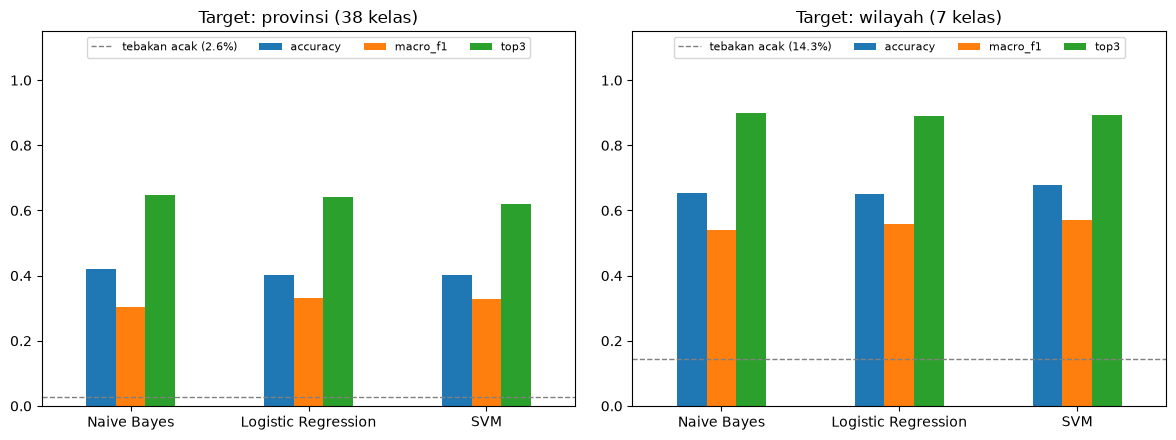

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, target in zip(axes, TARGET):
    d = metrik[(metrik["target"] == target) & (metrik["model"].isin(MODEL))].set_index("model")
    d[["accuracy", "macro_f1", "top3"]].plot.bar(ax=ax, rot=0, ylim=(0, 1.15))
    acak = 1 / df[target].nunique()
    ax.axhline(acak, color="gray", linestyle="--", linewidth=1, label=f"tebakan acak ({acak:.1%})")
    ax.set_title(f"Target: {target} ({df[target].nunique()} kelas)")
    ax.set_xlabel("")
    ax.legend(loc="upper center", ncol=4, fontsize=8)
plt.tight_layout()
FIGS.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGS / "02_perbandingan_model.png", dpi=150)
plt.show()

## 4. Pilihan model

Pilihan dibuat dari macro-F1, ditambah dua kebutuhan proyek:

1. Dashboard perlu **probabilitas** untuk menampilkan 3 provinsi teratas beserta persentasenya.
2. Analisis n-gram khas (Tahap 5) perlu **koefisien per kelas** yang bisa ditafsirkan.

Hanya Logistic Regression yang memenuhi keduanya. Jadi kalau selisih macro-F1 Logistic Regression dengan model terbaik kecil (kurang dari 0,02), Logistic Regression yang dipakai untuk target itu.

In [6]:
pilihan = {}
for target in TARGET:
    d = metrik[(metrik["target"] == target) & (metrik["model"].isin(MODEL))].set_index("model")
    terbaik = d["macro_f1"].idxmax()
    selisih = d.loc[terbaik, "macro_f1"] - d.loc["Logistic Regression", "macro_f1"]
    pilihan[target] = "Logistic Regression" if selisih < 0.02 else terbaik
    print(f"{target}: macro-F1 terbaik = {terbaik} ({d.loc[terbaik, 'macro_f1']:.3f}), "
          f"selisih dengan LR = {selisih:.3f} -> dipakai: {pilihan[target]}")

provinsi: macro-F1 terbaik = Logistic Regression (0.330), selisih dengan LR = 0.000 -> dipakai: Logistic Regression
wilayah: macro-F1 terbaik = SVM (0.571), selisih dengan LR = 0.014 -> dipakai: Logistic Regression


## 5. Simpan model

Model yang disimpan dilatih ulang dengan **seluruh data**, supaya dashboard dan generator memakai pengetahuan sebanyak mungkin. Angka evaluasi di atas tetap berasal dari data uji yang dipisah, jadi tetap jujur.

Yang disimpan adalah pipeline lengkap (vectorizer + model). Cara pakainya:

```python
model = joblib.load("models/best_provinsi.joblib")
from src.clean import clean_nama
model.predict([clean_nama("Cikalong Wetan")])
```

In [7]:
MODELS.mkdir(parents=True, exist_ok=True)
for target in TARGET:
    pipe = Pipeline([("tfidf", buat_vectorizer()), ("model", buat_model(pilihan[target]))])
    pipe.fit(df["nama_bersih"], df[target])
    path = MODELS / f"best_{target}.joblib"
    joblib.dump(pipe, path, compress=3)
    print(f"{path.relative_to(ROOT)}: {pilihan[target]}, {path.stat().st_size / 1e6:.1f} MB")

models\best_provinsi.joblib: Logistic Regression, 8.3 MB


models\best_wilayah.joblib: Logistic Regression, 1.7 MB


## 6. Coba tebak

Contoh nama yang dikarang sendiri, bukan diambil dari data.

In [8]:
import sys
sys.path.insert(0, str(ROOT))
from src.clean import clean_nama

model_prov = joblib.load(MODELS / "best_provinsi.joblib")
contoh = ["Cikalong Wetan", "Sidorejo Kidul", "Lumban Sitorus", "Gampong Meunasah Baro", "Kampung Yoka", "Tanjung Selor Hilir"]
proba = model_prov.predict_proba([clean_nama(n) for n in contoh])
for nama, p in zip(contoh, proba):
    top = np.argsort(-p)[:3]
    tebakan = ", ".join(f"{model_prov.classes_[i]} ({p[i]:.0%})" for i in top)
    print(f"{nama:24s} -> {tebakan}")

Cikalong Wetan           -> Jawa Barat (84%), Banten (11%), Jawa Tengah (3%)
Sidorejo Kidul           -> Jawa Timur (45%), Jawa Tengah (44%), Daerah Istimewa Yogyakarta (2%)
Lumban Sitorus           -> Sumatera Utara (91%), Sumatera Barat (3%), Papua Barat Daya (1%)
Gampong Meunasah Baro    -> Aceh (100%), Jambi (0%), Banten (0%)
Kampung Yoka             -> Papua (21%), Maluku Utara (12%), Papua Barat (12%)
Tanjung Selor Hilir      -> Kalimantan Utara (83%), Kalimantan Selatan (3%), Kalimantan Barat (3%)


## 7. Catatan untuk P2 (lanjutan)

- Tuning yang bisa dicoba: rentang n-gram (misalnya 1 sampai 5), `analyzer="char"` vs `"char_wb"`, nilai `C` pada LR dan SVM, `alpha` pada NB.
- Random Forest (opsional) bisa ditambahkan sebagai pembanding keluarga model pohon. Batasi fiturnya dengan `SelectKBest`.
- Kalau ada perubahan pengaturan, jalankan ulang seluruh notebook (Restart and Run All) supaya `metrics_baseline.csv` dan model tersimpan ikut diperbarui.